In [2]:
from pathlib import Path
import kagglehub

In [ ]:
data_dir = Path().resolve() / "Data"

path = kagglehub.dataset_download(
    "mohankrishnathalla/global-house-purchase-decision-dataset",
    output_dir=str(data_dir)
)

100%|██████████| 7.42M/7.42M [00:01<00:00, 5.43MB/s]

Extracting files...


In [3]:
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import dagshub
import mlflow
import mlflow.tensorflow
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [4]:
data_dir = Path().resolve() / "Data"

df = pd.read_csv(data_dir/"global_house_purchase_dataset.csv")
df.head()

,property_id,country,city,property_type,furnishing_status,property_size_sqft,price,constructed_year,previous_owners,rooms,...,customer_salary,loan_amount,loan_tenure_years,monthly_expenses,down_payment,emi_to_income_ratio,satisfaction_score,neighbourhood_rating,connectivity_score,decision
0,1,France,Marseille,Farmhouse,Semi-Furnished,991,412935,1989,6,6,...,10745,193949,15,6545,218986,0.16,1,5,6,0
1,2,South Africa,Cape Town,Apartment,Semi-Furnished,1244,224538,1990,4,8,...,16970,181465,20,8605,43073,0.08,9,1,2,0
2,3,South Africa,Johannesburg,Farmhouse,Semi-Furnished,4152,745104,2019,5,2,...,21914,307953,30,2510,437151,0.09,6,8,1,0
3,4,Germany,Frankfurt,Farmhouse,Semi-Furnished,3714,1110959,2008,1,3,...,17980,674720,15,8805,436239,0.33,2,6,6,0
4,5,South Africa,Johannesburg,Townhouse,Fully-Furnished,531,99041,2007,6,3,...,17676,65833,25,8965,33208,0.03,3,3,4,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 25 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   property_id              200000 non-null  int64  
 1   country                  200000 non-null  object 
 2   city                     200000 non-null  object 
 3   property_type            200000 non-null  object 
 4   furnishing_status        200000 non-null  object 
 5   property_size_sqft       200000 non-null  int64  
 6   price                    200000 non-null  int64  
 7   constructed_year         200000 non-null  int64  
 8   previous_owners          200000 non-null  int64  
 9   rooms                    200000 non-null  int64  
 10  bathrooms                200000 non-null  int64  
 11  garage                   200000 non-null  int64  
 12  garden                   200000 non-null  int64  
 13  crime_cases_reported     200000 non-null  int64  
 14  lega

In [7]:
df.describe()

,property_id,property_size_sqft,price,constructed_year,previous_owners,rooms,bathrooms,garage,garden,crime_cases_reported,...,customer_salary,loan_amount,loan_tenure_years,monthly_expenses,down_payment,emi_to_income_ratio,satisfaction_score,neighbourhood_rating,connectivity_score,decision
count,200000.000000,200000.000000,2.000000e+05,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,...,200000.000000,2.000000e+05,200000.000000,200000.000000,2.000000e+05,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,100000.500000,3195.633460,1.215365e+06,1991.487770,3.001370,4.513855,2.760030,0.499350,0.500215,1.229065,...,46528.625830,7.597583e+05,19.986375,10559.693105,4.556068e+05,0.195387,5.498650,5.505240,5.495615,0.230340
std,57735.171256,1613.322287,8.236633e+05,18.494064,2.002198,2.295669,1.840959,0.500001,0.500001,1.185336,...,27997.353766,5.489401e+05,7.081080,5427.241879,3.629865e+05,0.219689,2.875361,2.870945,2.870206,0.421052
min,1.000000,400.000000,5.628800e+04,1960.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,2000.000000,2.350400e+04,10.000000,500.000000,8.966000e+03,0.000000,1.000000,1.000000,1.000000,0.000000
25%,50000.750000,1802.000000,5.659895e+05,1975.000000,1.000000,3.000000,1.000000,0.000000,0.000000,0.000000,...,21450.000000,3.372802e+05,15.000000,5770.000000,1.849592e+05,0.070000,3.000000,3.000000,3.000000,0.000000
50%,100000.500000,3190.000000,1.023429e+06,1991.000000,3.000000,5.000000,2.000000,0.000000,1.000000,1.000000,...,41465.000000,6.269325e+05,20.000000,10520.000000,3.561700e+05,0.130000,5.000000,5.000000,5.000000,0.000000
75%,150000.250000,4589.000000,1.725556e+06,2008.000000,5.000000,7.000000,4.000000,1.000000,1.000000,2.000000,...,70805.000000,1.058416e+06,25.000000,15260.000000,6.257352e+05,0.240000,8.000000,8.000000,8.000000,0.000000
max,200000.000000,6000.000000,4.202732e+06,2023.000000,6.000000,8.000000,8.000000,1.000000,1.000000,10.000000,...,100000.000000,3.520150e+06,30.000000,20000.000000,2.492723e+06,3.460000,10.000000,10.000000,10.000000,1.000000


Podemos notar las siguientes variables y ver cuales iran en la paguina web y cuales son las que le pediremos al cliente para poder dar una probabilidad de compra.

### Características de la Casa (y su entorno)
Datos propios del inmueble que el vendedor ya conoce de su catálogo:
* **`country`**: País donde se ubica la propiedad.
* **`city`**: Ciudad donde se ubica la propiedad.
* **`property_type`**: Tipo de inmueble (casa, departamento, villa, etc.).
* **`furnishing_status`**: Estado de amueblado (amueblada, semi-amueblada, sin amueblar).
* **`property_size_sqft`**: Tamaño de la propiedad en pies cuadrados.
* **`price`**: Precio de venta de la casa.
* **`constructed_year`**: Año de construcción.
* **`previous_owners`**: Número de dueños anteriores.
* **`rooms`**: Número de habitaciones.
* **`bathrooms`**: Número de baños.
* **`garage`**: Indica si cuenta con garaje.
* **`garden`**: Indica si cuenta con jardín.
* **`crime_cases_reported`**: Casos de criminalidad reportados en la zona.
* **`legal_cases_on_property`**: Casos legales pendientes sobre la propiedad.
* **`neighbourhood_rating`**: Calificación del vecindario.
* **`connectivity_score`**: Nivel de conectividad/acceso a transporte y servicios.

### Características del Cliente
* **`customer_salary`**: Salario del cliente.
* **`monthly_expenses`**: Gastos mensuales del cliente.
* **`down_payment`**: Enganche (pago inicial) que el cliente puede dar.
* **`loan_amount`**: Monto del préstamo hipotecario solicitado.
* **`loan_tenure_years`**: Plazo del préstamo en años.
* **`emi_to_income_ratio`**: Relación entre la cuota mensual del préstamo y el ingreso del cliente *(dato calculable automáticamente en la app)*.
* **`satisfaction_score`**: Nivel de satisfacción/interés del cliente con la propiedad.

### Predicción (Target / Salida)
* **`decision`**: Variable objetivo binaria (`1` = El cliente compra la casa, `0` = No la compra).

### Variable a descartar
* **`property_id`**: Identificador único de registro. No aporta valor predictivo.

In [5]:
Y = df["decision"]
X = df.drop(columns=["property_id", "decision"])

# 70% entrenamiento, 20% prueba y 10% validación
X_train, X_temp, y_train, y_temp = train_test_split(
    X, Y, test_size=0.30, random_state=42, stratify=Y
)

# el 30% temporal -> 1/3 para validación (10%) y 2/3 para prueba (20%)
X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp, test_size=1/3, random_state=42, stratify=y_temp
)

print(f"Entrenamiento: {len(X_train)} ({len(X_train)/len(X):.0%})")
print(f"Prueba:        {len(X_test)} ({len(X_test)/len(X):.0%})")
print(f"Validación:    {len(X_val)} ({len(X_val)/len(X):.0%})")

Entrenamiento: 140000 (70%)
Prueba:        40000 (20%)
Validación:    20000 (10%)


In [6]:
# columnas de texto y numéricas
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
num_cols = X.select_dtypes(exclude=["object"]).columns.tolist()

# escalamos los números y aplicamos One-Hot Encoding al texto
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
    ]
)

# Ajustamos solo con los datos de train y transformamos con ese ajuste los 3 conjuntos
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc   = preprocessor.transform(X_val)
X_test_proc  = preprocessor.transform(X_test)

print(f"Columnas finales de entrada para la red neuronal: {X_train_proc.shape[1]}")

# Guardamos el preprocesador para cargarlo después en la app web
joblib.dump(preprocessor, "preprocessor.joblib")

Columnas finales de entrada para la red neuronal: 81


['preprocessor.joblib']

In [11]:
dagshub.init(repo_owner='DRACDARKTIME', repo_name='PredictionHousePurchase', mlflow=True)
mlflow.tensorflow.autolog()


Initialized MLflow to track repo "DRACDARKTIME/PredictionHousePurchase"

Repository DRACDARKTIME/PredictionHousePurchase initialized!

2026/11/24 09:33:23 WARNING mlflow.utils.autologging_utils: MLflow tensorflow autologging is known to be compatible with 2.18.1 <= tensorflow, but the installed version is 2.16.1. If you encounter errors during autologging, try upgrading / downgrading tensorflow to a compatible version, or try upgrading MLflow.


In [ ]:
model = keras.Sequential([
    layers.Input(shape=(X_train_proc.shape[1],)), 
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")       
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

with mlflow.start_run(run_name="keras_mlp_base"):
    history = model.fit(
        X_train_proc, y_train,
        validation_data=(X_val_proc, y_val),
        epochs=30,
        batch_size=256,
        callbacks=[early_stop],
        verbose=1
    )

    test_loss, test_acc, test_auc = model.evaluate(X_test_proc, y_test, verbose=0)
    mlflow.log_metrics({
        "test_loss": test_loss,
        "test_accuracy": test_acc,
        "test_auc": test_auc
    })
    print(f"\nResultados en Prueba -> Loss: {test_loss:.4f} | Accuracy: {test_acc:.4f} | AUC: {test_auc:.4f}")

model.save("modelo_casas.keras")

2026/11/24 00:02:22 WARNING mlflow.utils.autologging_utils: MLflow tensorflow autologging is known to be compatible with 2.18.1 <= tensorflow, but the installed version is 2.16.1. If you encounter errors during autologging, try upgrading / downgrading tensorflow to a compatible version, or try upgrading MLflow.
2026-11-24 00:02:22.182142: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-11-24 00:02:22.327654: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-11-24 00:02:

Epoch 1/30


I0000 00:00:1795500147.875242  534333 service.cc:145] XLA service 0x7f8e64009190 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795500147.875445  534333 service.cc:153]   StreamExecutor device (0): NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9
2026-11-24 00:02:27.917031: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-11-24 00:02:28.103153: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


 34/547 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6817 - auc: 0.5344 - loss: 0.6043  

I0000 00:00:1795500150.017481  534333 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


547/547 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8612 - auc: 0.8908 - loss: 0.2981

... (9 outputs left out)

547/547 ━━━━━━━━━━━━━━━━━━━━ 16s 28ms/step - accuracy: 0.9992 - auc: 1.0000 - loss: 0.0023 - val_accuracy: 0.9992 - val_auc: 1.0000 - val_loss: 0.0017
Epoch 13/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9990 - auc: 1.0000 - loss: 0.0024 - val_accuracy: 0.9990 - val_auc: 1.0000 - val_loss: 0.0026
Epoch 14/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9991 - auc: 1.0000 - loss: 0.0020 - val_accuracy: 0.9994 - val_auc: 1.0000 - val_loss: 0.0017
Epoch 15/30
543/547 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9993 - auc: 1.0000 - loss: 0.0019

547/547 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step - accuracy: 0.9993 - auc: 1.0000 - loss: 0.0019 - val_accuracy: 0.9994 - val_auc: 1.0000 - val_loss: 0.0014
Epoch 16/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9996 - auc: 1.0000 - loss: 0.0013 - val_accuracy: 0.9987 - val_auc: 1.0000 - val_loss: 0.0031
Epoch 17/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9993 - auc: 1.0000 - loss: 0.0020 - val_accuracy: 0.9992 - val_auc: 1.0000 - val_loss: 0.0017
Epoch 18/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9995 - auc: 1.0000 - loss: 0.0014 - val_accuracy: 0.9994 - val_auc: 1.0000 - val_loss: 0.0015
Epoch 19/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9994 - auc: 1.0000 - loss: 0.0015 - val_accuracy: 0.9991 - val_auc: 1.0000 - val_loss: 0.0022
Epoch 20/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9992 - auc: 1.0000 - loss: 0.0020 - val_accuracy: 0.9991 - val_auc: 1.0000 - val_loss: 0.0024
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step


2026/11/24 00:04:12 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



Resultados en Prueba -> Loss: 0.0012 | Accuracy: 0.9995 | AUC: 1.0000
🏃 View run keras_mlp_base at: https://dagshub.com/DRACDARKTIME/PredictionHousePurchase.mlflow/#/experiments/0/runs/6e9f25b81be344da92266d21aada7638
🧪 View experiment at: https://dagshub.com/DRACDARKTIME/PredictionHousePurchase.mlflow/#/experiments/0


=== Balance de clases (decision) ===
Clase 0: 153,932 registros (76.97%)
Clase 1: 46,068 registros (23.03%)

=== Reporte de Clasificación (Prueba) ===
               precision    recall  f1-score   support

No compra (0)       1.00      1.00      1.00     30787
Sí compra (1)       1.00      1.00      1.00      9213

     accuracy                           1.00     40000
    macro avg       1.00      1.00      1.00     40000
 weighted avg       1.00      1.00      1.00     40000



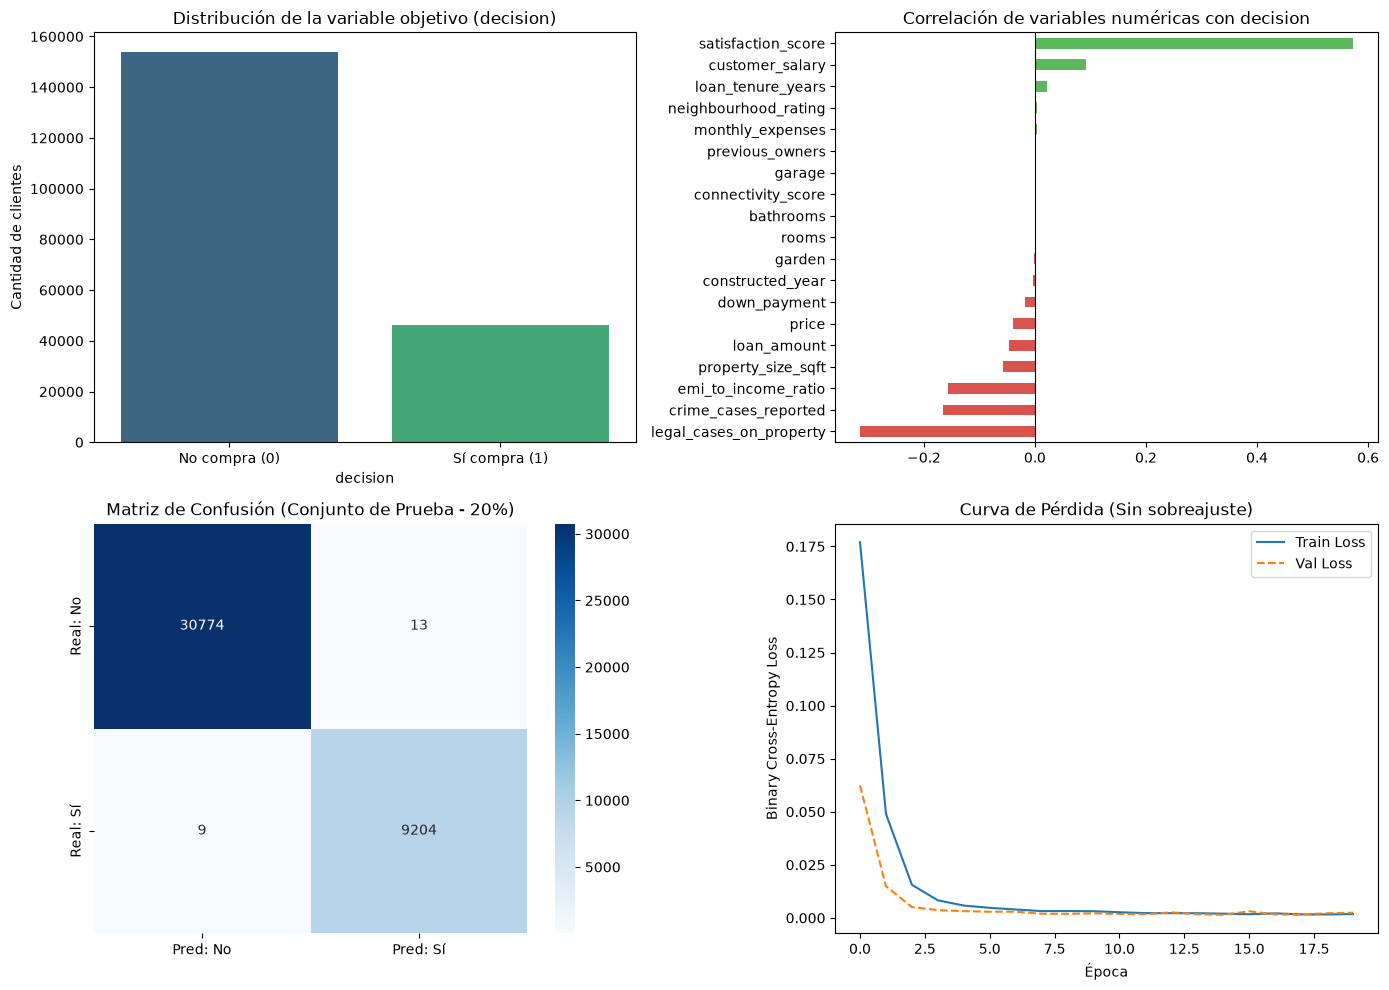

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

print("=== Balance de clases (decision) ===")
conteo = df["decision"].value_counts()
porcentaje = df["decision"].value_counts(normalize=True) * 100
for val in conteo.index:
    print(f"Clase {val}: {conteo[val]:,} registros ({porcentaje[val]:.2f}%)")

# Predicciones sobre el conjunto de prueba (20%)
y_pred_prob = model.predict(X_test_proc, verbose=0).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)

print("\n=== Reporte de Clasificación (Prueba) ===")
print(classification_report(y_test, y_pred, target_names=["No compra (0)", "Sí compra (1)"]))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Balance de clases
sns.countplot(x=df["decision"], ax=axes[0, 0], palette="viridis", hue=df["decision"], legend=False)
axes[0, 0].set_title("Distribución de la variable objetivo (decision)")
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_xticklabels(["No compra (0)", "Sí compra (1)"])
axes[0, 0].set_ylabel("Cantidad de clientes")

# Correlación de variables numéricas con 'decision'
corr = df.drop(columns=["property_id"]).corr(numeric_only=True)["decision"].drop("decision").sort_values()
corr.plot(kind="barh", ax=axes[0, 1], color=["#d9534f" if x < 0 else "#5cb85c" for x in corr])
axes[0, 1].set_title("Correlación de variables numéricas con decision")
axes[0, 1].axvline(0, color="black", linewidth=0.8)

# Matriz de Confusión en Prueba
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1, 0],
            xticklabels=["Pred: No", "Pred: Sí"], yticklabels=["Real: No", "Real: Sí"])
axes[1, 0].set_title("Matriz de Confusión (Conjunto de Prueba - 20%)")

# Curvas de Loss (Entrenamiento vs Validación)
axes[1, 1].plot(history.history["loss"], label="Train Loss")
axes[1, 1].plot(history.history["val_loss"], label="Val Loss", linestyle="--")
axes[1, 1].set_title("Curva de Pérdida (Sin sobreajuste)")
axes[1, 1].set_xlabel("Época")
axes[1, 1].set_ylabel("Binary Cross-Entropy Loss")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig("analisis_modelo.png", dpi=150)
plt.show()

Con base en el análisis de correlación, seleccionamos únicamente las 10 variables numéricas con mayor impacto en decision. Al prescindir de las variables categóricas y el ruido, simplificamos el preprocesamiento a un StandardScaler y ajustamos la arquitectura de la red para registrarla como un segundo experimento en DagsHub.

In [10]:
import joblib
import mlflow
import mlflow.tensorflow
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

features_clave = [
    "satisfaction_score",
    "customer_salary",
    "loan_tenure_years",
    "legal_cases_on_property",
    "crime_cases_reported",
    "emi_to_income_ratio",
    "property_size_sqft",
    "loan_amount",
    "price",
    "down_payment"
]

X_simple = df[features_clave]
Y = df["decision"]

# División estratificada 70% entrenamiento, 20% prueba, 10% validación
X_train_s, X_temp_s, y_train_s, y_temp_s = train_test_split(
    X_simple, Y, test_size=0.30, random_state=42, stratify=Y
)
X_test_s, X_val_s, y_test_s, y_val_s = train_test_split(
    X_temp_s, y_temp_s, test_size=1/3, random_state=42, stratify=y_temp_s
)

scaler_simple = StandardScaler()
X_train_s_proc = scaler_simple.fit_transform(X_train_s)
X_val_s_proc = scaler_simple.transform(X_val_s)
X_test_s_proc = scaler_simple.transform(X_test_s)

joblib.dump(scaler_simple, "scaler_simple.joblib")

['scaler_simple.joblib']

In [ ]:
model_simple = keras.Sequential([
    layers.Input(shape=(X_train_s_proc.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

model_simple.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

with mlflow.start_run(run_name="keras_mlp_simplificado"):
    mlflow.log_param("num_features", len(features_clave))
    mlflow.log_param("features", features_clave)

    history_simple = model_simple.fit(
        X_train_s_proc, y_train_s,
        validation_data=(X_val_s_proc, y_val_s),
        epochs=30,
        batch_size=256,
        callbacks=[early_stop],
        verbose=1
    )

    test_loss, test_acc, test_auc = model_simple.evaluate(X_test_s_proc, y_test_s, verbose=0)
    mlflow.log_metrics({
        "test_loss": test_loss,
        "test_accuracy": test_acc,
        "test_auc": test_auc
    })
    print(f"Prueba (Simplificado) -> Loss: {test_loss:.4f} | Accuracy: {test_acc:.4f} | AUC: {test_auc:.4f}")

model_simple.save("modelo_casas_simple.keras")

2026/11/24 00:17:43 WARNING mlflow.tensorflow: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'


Epoch 1/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8698 - auc: 0.9016 - loss: 0.3233

547/547 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.8699 - auc: 0.9017 - loss: 0.3231 - val_accuracy: 0.9804 - val_auc: 0.9975 - val_loss: 0.0624
Epoch 2/30
534/547 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9743 - auc: 0.9961 - loss: 0.0695

547/547 ━━━━━━━━━━━━━━━━━━━━ 23s 42ms/step - accuracy: 0.9744 - auc: 0.9962 - loss: 0.0692 - val_accuracy: 0.9930 - val_auc: 0.9998 - val_loss: 0.0208
Epoch 3/30
518/547 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9908 - auc: 0.9993 - loss: 0.0293

547/547 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - accuracy: 0.9909 - auc: 0.9993 - loss: 0.0291 - val_accuracy: 0.9973 - val_auc: 1.0000 - val_loss: 0.0092
Epoch 4/30
540/547 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9950 - auc: 0.9997 - loss: 0.0169

547/547 ━━━━━━━━━━━━━━━━━━━━ 15s 28ms/step - accuracy: 0.9950 - auc: 0.9997 - loss: 0.0169 - val_accuracy: 0.9984 - val_auc: 1.0000 - val_loss: 0.0057
Epoch 5/30
527/547 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9962 - auc: 0.9999 - loss: 0.0111

... (15 outputs left out)

547/547 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.9997 - auc: 1.0000 - loss: 0.0012 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 2.0749e-04
Epoch 30/30
543/547 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9997 - auc: 1.0000 - loss: 7.7147e-04

547/547 ━━━━━━━━━━━━━━━━━━━━ 16s 29ms/step - accuracy: 0.9997 - auc: 1.0000 - loss: 7.7208e-04 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 1.6019e-04
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step


2026/11/24 00:22:22 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Prueba (Simplificado) -> Loss: 0.0001 | Accuracy: 1.0000 | AUC: 1.0000
🏃 View run keras_mlp_simplificado at: https://dagshub.com/DRACDARKTIME/PredictionHousePurchase.mlflow/#/experiments/0/runs/faf5dbd7d2a447009d26c56e1bb742df
🧪 View experiment at: https://dagshub.com/DRACDARKTIME/PredictionHousePurchase.mlflow/#/experiments/0


Por ultimo entrenaremos un modelo con los datos de target balanceados 50% sí 50% no.

In [12]:
import pandas as pd
import mlflow
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

train_df = X_train_s.copy()
train_df["decision"] = y_train_s.values

clase_1 = train_df[train_df["decision"] == 1]
clase_0 = train_df[train_df["decision"] == 0].sample(n=len(clase_1), random_state=42)

train_bal = pd.concat([clase_1, clase_0]).sample(frac=1, random_state=42)
X_train_b = train_bal.drop(columns=["decision"])
y_train_b = train_bal["decision"]

print(y_train_b.value_counts(normalize=True))

scaler_bal = StandardScaler()
X_train_b_proc = scaler_bal.fit_transform(X_train_b)
X_val_b_proc = scaler_bal.transform(X_val_s)
X_test_b_proc = scaler_bal.transform(X_test_s)

model_bal = keras.Sequential([
    layers.Input(shape=(X_train_b_proc.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

model_bal.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

with mlflow.start_run(run_name="keras_mlp_balanceado_50_50"):
    mlflow.log_param("balancing", "undersampling_50_50_train_only")
    mlflow.log_param("train_samples", len(X_train_b))

    history_bal = model_bal.fit(
        X_train_b_proc, y_train_b,
        validation_data=(X_val_b_proc, y_val_s),
        epochs=30,
        batch_size=256,
        callbacks=[early_stop],
        verbose=1
    )

    test_loss, test_acc, test_auc = model_bal.evaluate(X_test_b_proc, y_test_s, verbose=0)
    mlflow.log_metrics({
        "test_loss": test_loss,
        "test_accuracy": test_acc,
        "test_auc": test_auc
    })
    print(f"Prueba (Balanceado 50/50) -> Loss: {test_loss:.4f} | Accuracy: {test_acc:.4f} | AUC: {test_auc:.4f}")

decision
1    0.5
0    0.5
Name: proportion, dtype: float64


2026-11-24 09:33:58.802075: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-11-24 09:33:58.829093: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-11-24 09:33:58.832976: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

Epoch 1/30


I0000 00:00:1795534448.053263 3616632 service.cc:145] XLA service 0x7f6790009870 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795534448.053309 3616632 service.cc:153]   StreamExecutor device (0): NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9
2026-11-24 09:34:08.073214: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-11-24 09:34:08.202216: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


 35/252 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4994 - auc: 0.4220 - loss: 0.7573  

I0000 00:00:1795534450.174203 3616632 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


... (17 outputs left out)

252/252 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9989 - auc: 1.0000 - loss: 0.0028 - val_accuracy: 0.9998 - val_auc: 1.0000 - val_loss: 0.0011
Epoch 29/30
218/252 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9993 - auc: 1.0000 - loss: 0.0021

252/252 ━━━━━━━━━━━━━━━━━━━━ 22s 88ms/step - accuracy: 0.9993 - auc: 1.0000 - loss: 0.0021 - val_accuracy: 0.9998 - val_auc: 1.0000 - val_loss: 9.3441e-04
Epoch 30/30
252/252 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9993 - auc: 1.0000 - loss: 0.0023 - val_accuracy: 0.9991 - val_auc: 1.0000 - val_loss: 0.0016
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step


2026/11/24 09:37:38 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Prueba (Balanceado 50/50) -> Loss: 0.0008 | Accuracy: 0.9999 | AUC: 1.0000
🏃 View run keras_mlp_balanceado_50_50 at: https://dagshub.com/DRACDARKTIME/PredictionHousePurchase.mlflow/#/experiments/0/runs/40f73cfc521d4b808c6eaf33d7d47daa
🧪 View experiment at: https://dagshub.com/DRACDARKTIME/PredictionHousePurchase.mlflow/#/experiments/0


Podemos notar que el modelo sigue siendo bastante bueno incluso en el test donde los datos no estan balanceados
Como el mejor modelo gue con datos desbalanceados y con 10 entradas escogeremos ese para llevarlo a producción.